# Sweep results
Reads `out/*/` (written by `run.py`). Re-run all cells after new runs finish.

In [1]:
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

rows, hists = [], {}
for d in sorted(glob.glob("out/*/")):
    name = os.path.basename(d.rstrip("/"))
    if not (os.path.exists(d+"config.json") and os.path.exists(d+"results.json")):
        continue                                   # still running or failed
    cfg = json.load(open(d+"config.json")); res = json.load(open(d+"results.json"))
    if cfg["model"] == "baselines":                # {baseline: {pair: metrics}}
        for bname, per_pair in res.items():
            for pair, m in per_pair.items():
                rows.append({"run": bname, "model": "baseline", "overrides": "", "min": None, "pair": pair, **m})
    else:                                          # {ALL/pair: metrics}
        hists[name] = json.load(open(d+"history.json"))
        for pair, m in res.items():
            rows.append({"run": name, "model": cfg["model"], "overrides": " ".join(cfg["overrides"]),
                         "min": cfg["minutes"], "pair": pair, **m})
df = pd.DataFrame(rows)
print(len(df.run.unique()), "runs loaded")

19 runs loaded


## Pooled (ALL), sorted by switch PR-AUC

In [2]:
cols = ["model","overrides","switch_PR_AUC","switch_F1","switch_F1max","dur_macro_F1","dur_acc","switch_P","switch_R","joint_acc","val_ce_sw","val_ce_dur","min"]
cols = [k for k in cols if k in df.columns]          # old runs may lack the newer columns
a = df[df.pair=="ALL"].set_index("run")[cols]
a["score"] = 0.5*(a.switch_PR_AUC + a.dur_macro_F1)    # same as trainer.select_score
a.sort_values("score", ascending=False)

,model,overrides,switch_PR_AUC,switch_F1,switch_F1max,dur_macro_F1,dur_acc,switch_P,switch_R,joint_acc,val_ce_sw,val_ce_dur,min,score
run,,,,,,,,,,,,,,
all_qw4b_8k_dur02,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.824,0.736,0.747,0.622,0.638,0.678,0.805,0.911,0.1512,0.8072,370.2,0.7230
all_qwen_8k_dur02,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.808,0.721,0.732,0.612,0.629,0.664,0.790,0.908,0.1592,0.8247,112.5,0.7100
all_qwen_8k_dur05,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.805,0.719,0.730,0.614,0.629,0.661,0.789,0.907,0.1610,0.8228,111.5,0.7095
all_qwen_8k_dur02_seed1,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.809,0.721,0.732,0.609,0.627,0.664,0.790,0.906,0.1609,0.8238,111.4,0.7090
all_qwen_8k_dur08,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.801,0.716,0.727,0.614,0.628,0.656,0.787,0.906,0.1631,0.8234,113.0,0.7075
all_xlmr_8k_dur02,xlmr,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 EPOCHS=2...",0.804,0.715,0.729,0.611,0.633,0.649,0.796,0.905,0.1646,0.8194,137.1,0.7075
all_xlmr_8k_dur02_win32,xlmr,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 EPOCHS=2...",0.803,0.716,0.728,0.612,0.633,0.650,0.796,0.905,0.1644,0.8192,132.1,0.7075
all_xlmr_8k_dur05,xlmr,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 EPOCHS=2...",0.800,0.713,0.726,0.612,0.633,0.645,0.797,0.904,0.1672,0.8165,137.0,0.7060
all_qwen_8k_dur10,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.798,0.713,0.725,0.612,0.626,0.653,0.786,0.905,0.1645,0.8240,111.6,0.7050


## Per pair

In [3]:
for metric in ["switch_PR_AUC", "switch_F1", "dur_macro_F1", "dur_acc", "joint_acc"]:
    if metric not in df.columns: continue
    print("\n==", metric, "==")
    display(df[df.pair!="ALL"].pivot(index="run", columns="pair", values=metric))


== switch_PR_AUC ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B0 never-switch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B1 lookup,0.476,0.409,0.409,0.415,0.358,0.429,0.341,0.573,0.393,0.369,0.252,0.313
B2 char-ngram LR,0.591,0.555,0.514,0.543,0.581,0.549,0.690,0.862,0.530,0.494,0.420,0.494
all_qw4b_8k_dur02,0.821,0.845,0.803,0.826,0.850,0.801,0.864,0.950,0.772,0.772,0.714,0.826
all_qwen_2k_dur02,0.796,0.801,0.768,0.753,0.828,0.773,0.841,0.943,0.720,0.727,0.665,0.775
all_qwen_5k_dur02,0.812,0.834,0.788,0.791,0.826,0.775,0.855,0.949,0.775,0.715,0.674,0.795
all_qwen_8k_dur02,0.802,0.834,0.781,0.805,0.832,0.782,0.853,0.947,0.755,0.750,0.690,0.808
all_qwen_8k_dur02_seed1,0.812,0.841,0.786,0.796,0.849,0.772,0.844,0.942,0.772,0.749,0.689,0.812



== switch_F1 ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.231,0.215,0.214,0.205,0.141,0.202,0.127,0.280,0.237,0.207,0.164,0.151
B0 never-switch,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
B1 lookup,0.399,0.356,0.337,0.332,0.330,0.336,0.171,0.494,0.375,0.288,0.216,0.212
B2 char-ngram LR,0.444,0.422,0.420,0.445,0.386,0.414,0.536,0.697,0.441,0.423,0.392,0.415
all_qw4b_8k_dur02,0.730,0.784,0.726,0.743,0.747,0.729,0.762,0.880,0.699,0.697,0.643,0.740
all_qwen_2k_dur02,0.722,0.747,0.697,0.692,0.727,0.696,0.746,0.863,0.661,0.659,0.617,0.691
all_qwen_5k_dur02,0.716,0.774,0.707,0.722,0.729,0.690,0.749,0.877,0.697,0.667,0.614,0.714
all_qwen_8k_dur02,0.712,0.766,0.714,0.727,0.732,0.713,0.749,0.875,0.688,0.679,0.623,0.728
all_qwen_8k_dur02_seed1,0.715,0.774,0.713,0.721,0.755,0.695,0.743,0.868,0.704,0.680,0.618,0.726



== dur_macro_F1 ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.174,0.184,0.166,0.184,0.127,0.187,0.227,0.183,0.157,0.159,0.159,0.213
B0 never-switch,0.174,0.184,0.166,0.184,0.127,0.187,0.227,0.183,0.157,0.159,0.159,0.213
B1 lookup,0.325,0.267,0.301,0.264,0.357,0.256,0.231,0.326,0.350,0.320,0.319,0.242
B2 char-ngram LR,0.489,0.484,0.507,0.475,0.556,0.458,0.540,0.546,0.492,0.483,0.508,0.481
all_qw4b_8k_dur02,0.601,0.596,0.613,0.598,0.618,0.581,0.597,0.636,0.635,0.592,0.639,0.587
all_qwen_2k_dur02,0.594,0.572,0.522,0.575,0.542,0.547,0.564,0.568,0.601,0.594,0.579,0.544
all_qwen_5k_dur02,0.585,0.598,0.586,0.582,0.575,0.576,0.577,0.615,0.622,0.581,0.585,0.576
all_qwen_8k_dur02,0.594,0.593,0.613,0.597,0.604,0.575,0.574,0.615,0.618,0.585,0.621,0.569
all_qwen_8k_dur02_seed1,0.573,0.589,0.604,0.584,0.603,0.580,0.579,0.617,0.615,0.577,0.612,0.583



== dur_acc ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.353,0.380,0.332,0.382,0.236,0.389,0.517,0.378,0.308,0.313,0.314,0.469
B0 never-switch,0.353,0.380,0.332,0.382,0.236,0.389,0.517,0.378,0.308,0.313,0.314,0.469
B1 lookup,0.428,0.378,0.417,0.377,0.500,0.357,0.324,0.425,0.456,0.453,0.415,0.332
B2 char-ngram LR,0.517,0.521,0.523,0.497,0.591,0.484,0.649,0.595,0.511,0.531,0.513,0.536
all_qw4b_8k_dur02,0.615,0.616,0.620,0.612,0.654,0.592,0.714,0.661,0.638,0.622,0.636,0.649
all_qwen_2k_dur02,0.609,0.596,0.530,0.588,0.597,0.555,0.688,0.601,0.608,0.628,0.581,0.605
all_qwen_5k_dur02,0.606,0.614,0.593,0.597,0.631,0.584,0.710,0.638,0.629,0.610,0.592,0.633
all_qwen_8k_dur02,0.608,0.615,0.621,0.611,0.648,0.587,0.705,0.641,0.622,0.618,0.620,0.633
all_qwen_8k_dur02_seed1,0.591,0.607,0.614,0.601,0.656,0.590,0.707,0.638,0.625,0.617,0.614,0.643



== joint_acc ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.046,0.046,0.040,0.044,0.018,0.044,0.035,0.062,0.041,0.036,0.028,0.038
B0 never-switch,0.870,0.880,0.880,0.886,0.924,0.888,0.932,0.837,0.866,0.885,0.911,0.919
B1 lookup,0.634,0.539,0.532,0.524,0.757,0.543,0.335,0.653,0.589,0.475,0.402,0.395
B2 char-ngram LR,0.677,0.691,0.702,0.730,0.778,0.704,0.889,0.813,0.679,0.731,0.798,0.819
all_qw4b_8k_dur02,0.882,0.903,0.892,0.899,0.935,0.898,0.950,0.908,0.874,0.890,0.908,0.931
all_qwen_2k_dur02,0.876,0.888,0.880,0.893,0.926,0.883,0.948,0.898,0.869,0.885,0.900,0.923
all_qwen_5k_dur02,0.872,0.898,0.886,0.895,0.912,0.891,0.947,0.903,0.872,0.878,0.898,0.927
all_qwen_8k_dur02,0.878,0.898,0.888,0.897,0.932,0.893,0.947,0.903,0.870,0.885,0.905,0.928
all_qwen_8k_dur02_seed1,0.871,0.898,0.889,0.895,0.925,0.891,0.947,0.898,0.873,0.886,0.901,0.930


## Training curves (val metrics per epoch, ALL)
Note `val_loss` is not comparable between XLM-R and Qwen3.

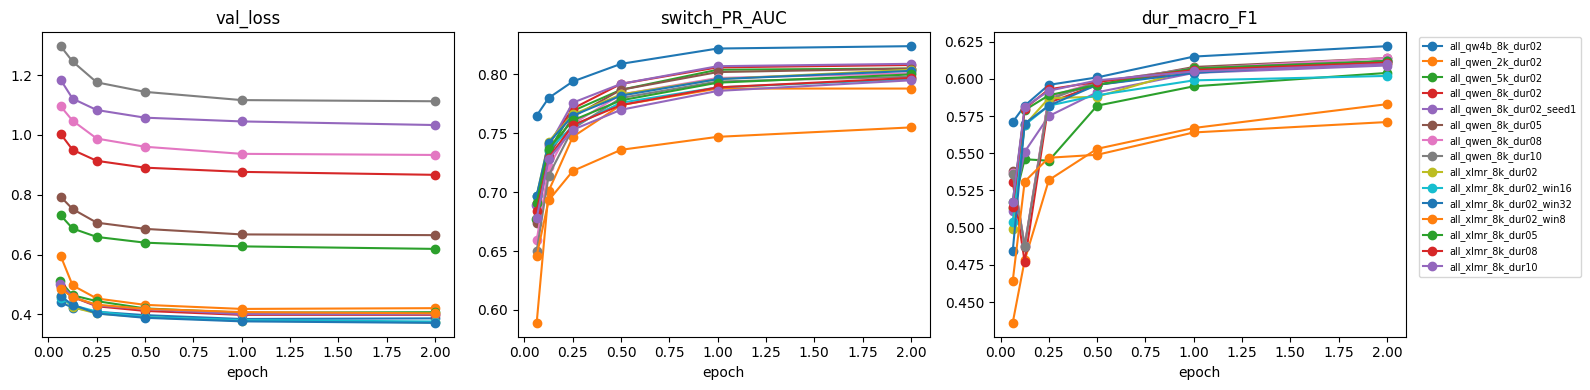

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
def unpack(h):
    # New: {"step","epoch","res"}; Old: one res dict/epoch
    if h and "res" in h[0]:
        return [e["epoch"] for e in h], [e["res"] for e in h]
    return list(range(1, len(h) + 1)), h

for name, h in hists.items():
    ep, rs = unpack(h)
    ax[0].plot(ep, [r["ALL"]["val_loss"] for r in rs], marker="o", label=name)
    ax[1].plot(ep, [r["ALL"]["switch_PR_AUC"] for r in rs], marker="o", label=name)
    ax[2].plot(ep, [r["ALL"]["dur_macro_F1"] for r in rs], marker="o", label=name)
for x, t in zip(ax, ["val_loss", "switch_PR_AUC", "dur_macro_F1"]):
    x.set_title(t); x.set_xlabel("epoch")
ax[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Loss convergence: total / Switch / Duration (train vs val)
Shown for the best neural run by `score`; set `RUNS` to plot others. Train loss = average over the steps since the previous validation. Needs runs made with the updated `trainer.py` (older `history.json` has no train loss).

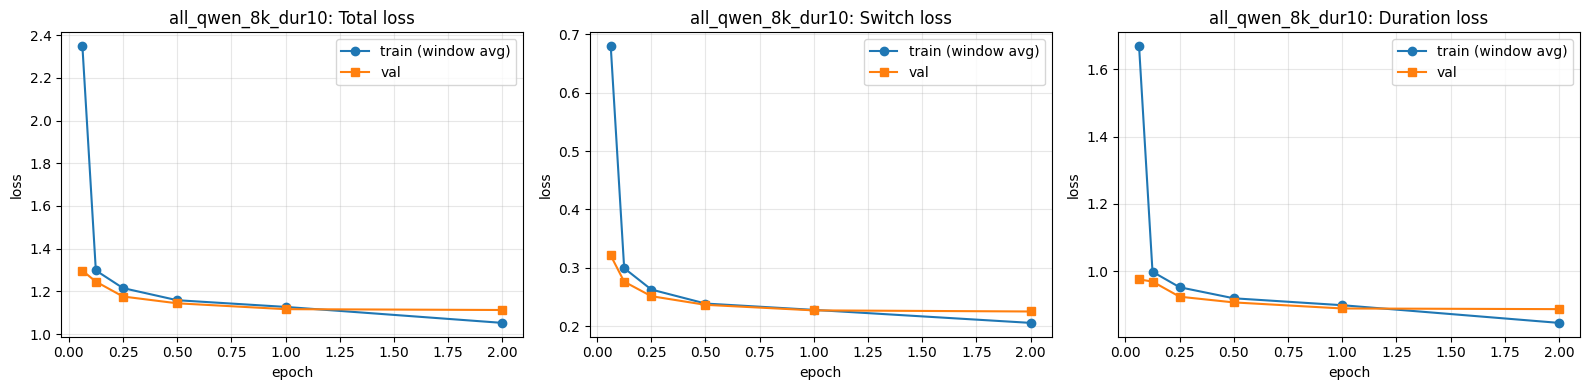

In [16]:
RUNS = [a[a.model != "baseline"].score.idxmax()]      # e.g. RUNS = ["all_qwen_8k_dur03", ...]
RUNS = ['all_qwen_8k_dur10']
def plot_run(name):
    h = hists[name]
    if not (h and "train" in h[0]):
        print(name, ": no train loss logged (run predates the update)"); return
    ep = [e["epoch"] for e in h]
    A = lambda k: [e["res"]["ALL"][k] for e in h]
    T = lambda k: [e["train"][k] for e in h]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for x, t, tr, va in zip(ax, ["Total loss", "Switch loss", "Duration loss"],
                            ["loss", "loss_sw", "loss_dur"], ["val_loss", "val_loss_sw", "val_loss_dur"]):
        x.plot(ep, T(tr), "o-", label="train (window avg)"); x.plot(ep, A(va), "s-", label="val")
        x.set_title(f"{name}: {t}"); x.set_xlabel("epoch"); x.set_ylabel("loss"); x.legend(); x.grid(alpha=.3)
    plt.tight_layout(); plt.show()

for r in RUNS: plot_run(r)

## Monitored metrics: Switch head (PR-AUC, Anticipatory F1) vs Duration head (Accuracy, Macro-F1)
Anticipatory F1 = positive-class (switch=1) F1; `max` = best threshold on this val set.

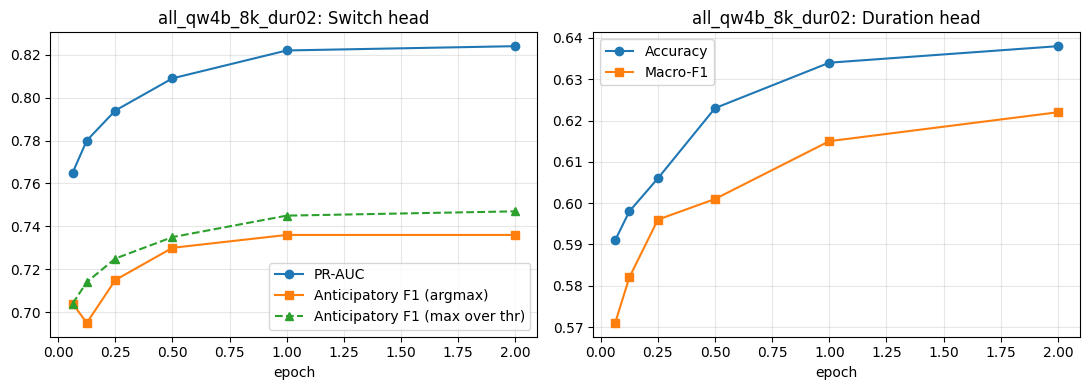

In [6]:
def plot_metrics(name):
    h = hists[name]
    if not (h and "res" in h[0] and "switch_F1max" in h[0]["res"]["ALL"]):
        print(name, ": run predates the updated metrics"); return
    ep = [e["epoch"] for e in h]
    A = lambda k: [e["res"]["ALL"][k] for e in h]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, A("switch_PR_AUC"), "o-", label="PR-AUC")
    ax[0].plot(ep, A("switch_F1"), "s-", label="Anticipatory F1 (argmax)")
    ax[0].plot(ep, A("switch_F1max"), "^--", label="Anticipatory F1 (max over thr)")
    ax[0].set_title(f"{name}: Switch head")
    ax[1].plot(ep, A("dur_acc"), "o-", label="Accuracy"); ax[1].plot(ep, A("dur_macro_F1"), "s-", label="Macro-F1")
    ax[1].set_title(f"{name}: Duration head")
    for x in ax: x.set_xlabel("epoch"); x.legend(); x.grid(alpha=.3)
    plt.tight_layout(); plt.show()

for r in RUNS: plot_metrics(r)

## Test: Anticipatory F1 and dur_acc per language pair (+ mean / std across pairs)
Reads `out/*/test_results.json`. Neural runs use the switch threshold searched on val; `STD` = sample std (ddof=1) across pairs, `ALL` excluded.


== TEST Anticipatory_F1 ==


pair,ALL,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en,MEAN,STD
run,,,,,,,,,,,,,,,
B0 always-switch,0.189,0.242,0.219,0.210,0.208,0.165,0.201,0.127,0.277,0.242,0.203,0.161,0.148,0.2002,0.0435
B0 never-switch,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0000,0.0000
B1 lookup,0.283,0.417,0.357,0.326,0.340,0.352,0.333,0.169,0.488,0.384,0.288,0.213,0.213,0.3233,0.0911
B2 char-ngram LR,0.445,0.449,0.427,0.411,0.438,0.415,0.402,0.525,0.686,0.452,0.416,0.375,0.413,0.4508,0.0827
all_qw4b_8k_dur02,0.747,0.746,0.795,0.726,0.756,0.761,0.724,0.771,0.882,0.721,0.708,0.632,0.759,0.7484,0.0587
all_qwen_2k_dur02,0.713,0.716,0.763,0.685,0.710,0.732,0.689,0.744,0.869,0.680,0.658,0.592,0.729,0.7139,0.0664
all_qwen_5k_dur02,0.727,0.727,0.775,0.705,0.729,0.743,0.706,0.757,0.875,0.696,0.680,0.605,0.741,0.7282,0.0636
all_qwen_8k_dur02,0.732,0.735,0.779,0.708,0.734,0.747,0.709,0.762,0.879,0.702,0.687,0.614,0.741,0.7331,0.0625
all_qwen_8k_dur02_seed1,0.732,0.734,0.777,0.710,0.734,0.743,0.710,0.760,0.877,0.701,0.687,0.613,0.746,0.7327,0.0620



== TEST dur_acc ==


pair,ALL,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en,MEAN,STD
run,,,,,,,,,,,,,,,
B0 always-switch,0.367,0.330,0.361,0.362,0.367,0.225,0.393,0.521,0.370,0.319,0.320,0.312,0.472,0.3627,0.0765
B0 never-switch,0.367,0.330,0.361,0.362,0.367,0.225,0.393,0.521,0.370,0.319,0.320,0.312,0.472,0.3627,0.0765
B1 lookup,0.403,0.448,0.372,0.392,0.386,0.478,0.384,0.328,0.417,0.470,0.444,0.414,0.336,0.4058,0.0485
B2 char-ngram LR,0.541,0.530,0.503,0.505,0.490,0.575,0.520,0.640,0.572,0.535,0.534,0.527,0.541,0.5393,0.0405
all_qw4b_8k_dur02,0.637,0.636,0.591,0.603,0.609,0.647,0.619,0.724,0.642,0.638,0.615,0.645,0.649,0.6348,0.0340
all_qwen_2k_dur02,0.611,0.610,0.567,0.582,0.584,0.630,0.591,0.699,0.623,0.621,0.583,0.610,0.613,0.6094,0.0344
all_qwen_5k_dur02,0.622,0.623,0.578,0.598,0.591,0.641,0.613,0.705,0.633,0.623,0.598,0.620,0.629,0.6210,0.0324
all_qwen_8k_dur02,0.626,0.617,0.586,0.598,0.600,0.637,0.614,0.708,0.634,0.626,0.601,0.630,0.637,0.6240,0.0315
all_qwen_8k_dur02_seed1,0.625,0.620,0.575,0.602,0.601,0.641,0.613,0.713,0.637,0.627,0.594,0.630,0.629,0.6235,0.0342


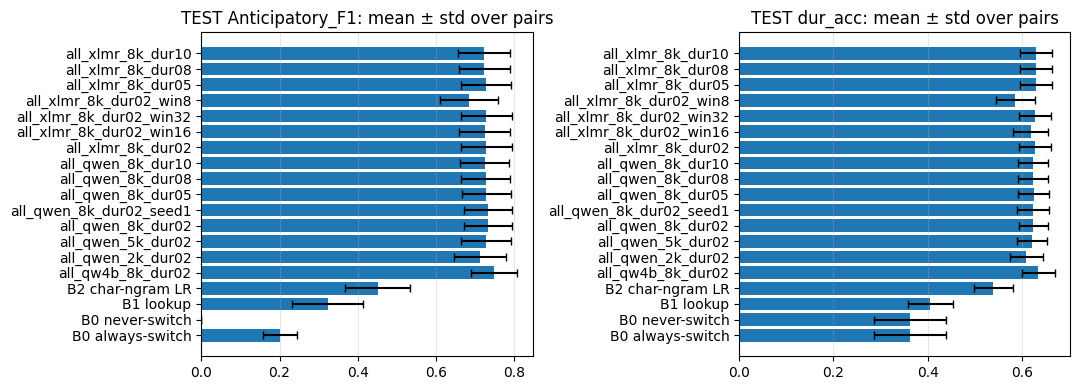

In [7]:
trows = []
for d in sorted(glob.glob("out/*/")):
    p = d + "test_results.json"
    if not os.path.exists(p): continue
    name = os.path.basename(d.rstrip("/")); cfg = json.load(open(d + "config.json")); tr = json.load(open(p))
    for run, per_pair in (tr.items() if cfg["model"] == "baselines" else [(name, tr)]):
        for pair, m in per_pair.items():
            trows.append({"run": run, "pair": pair, "Anticipatory_F1": m["switch_F1"], "dur_acc": m["dur_acc"]})
tdf = pd.DataFrame(trows)

def pair_table(metric):
    t = tdf.pivot(index="run", columns="pair", values=metric)
    pairs = [c for c in t.columns if c != "ALL"]
    t["MEAN"] = t[pairs].mean(axis=1); t["STD"] = t[pairs].std(axis=1, ddof=1)
    return t[["ALL"] + pairs + ["MEAN", "STD"]].round(4)

for metric in ["Anticipatory_F1", "dur_acc"]:
    print("\n== TEST", metric, "==")
    display(pair_table(metric))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for x, metric in zip(ax, ["Anticipatory_F1", "dur_acc"]):
    t = pair_table(metric)
    x.barh(t.index, t["MEAN"], xerr=t["STD"], capsize=3); x.set_title(f"TEST {metric}: mean ± std over pairs"); x.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()